In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)   # empty slices where a whole row was dropped
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

DATA = '../data'
X_train = np.load(f'{DATA}/train_cadences.npy', mmap_mode='r')   # (18000, 6, 16, 128) uint8
X_test  = np.load(f'{DATA}/test_cadences.npy', mmap_mode='r')    # (10000, 6, 16, 128) uint8
train = pd.read_csv(f'{DATA}/train_meta.csv')
test  = pd.read_csv(f'{DATA}/test_meta.csv')
print(X_train.shape, X_test.shape)
print(train.label.value_counts().to_dict())

(18000, 6, 16, 128) (10000, 6, 16, 128)
{'noise': 4211, 'rfi_persistent': 2892, 'rfi_intermittent': 2662, 'radar_chirp': 1849, 'satellite_pass': 1805, 'pulsar': 1629, 'scintillating_star': 1431, 'frb': 1042, 'eti_candidate': 479}


In [2]:
import numpy as np
import pandas as pd
import torch
import sklearn

print("PyTorch:", torch.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Device:", "CUDA GPU" if torch.cuda.is_available() else "CPU")

print("Raw training data:", X_train.shape)
print("Raw test data:", X_test.shape)
print("Labels:", train["label"].nunique())
print(train["label"].value_counts())

PyTorch: 2.14.1+cpu
Scikit-learn: 1.9.1
Device: CPU
Raw training data: (18000, 6, 16, 128)
Raw test data: (10000, 6, 16, 128)
Labels: 9
label
noise                 4211
rfi_persistent        2892
rfi_intermittent      2662
radar_chirp           1849
satellite_pass        1805
pulsar                1629
scintillating_star    1431
frb                   1042
eti_candidate          479
Name: count, dtype: int64


In [3]:
def prepare_cnn_input(X):
    X = np.asarray(X, dtype=np.float32)

    # Zero-valued pixels are missing.
    mask = X != 0

    # Normalize each sample and panel independently.
    valid_count = mask.sum(axis=(2, 3), keepdims=True)
    safe_count = np.maximum(valid_count, 1)

    observed = np.where(mask, X, 0.0)
    mean = observed.sum(axis=(2, 3), keepdims=True) / safe_count

    centered = np.where(mask, X - mean, 0.0)
    variance = (centered ** 2).sum(
        axis=(2, 3), keepdims=True
    ) / safe_count

    std = np.sqrt(variance)
    std = np.maximum(std, 1.0)

    normalized = np.where(mask, centered / std, 0.0)

    # CNN input: 6 normalized signal channels + 6 missingness masks.
    result = np.concatenate(
        [normalized, mask.astype(np.float32)],
        axis=1,
    )

    return result.astype(np.float32)


X_cnn = prepare_cnn_input(X_train)
X_cnn_test = prepare_cnn_input(X_test)

print("CNN training input:", X_cnn.shape)
print("CNN test input:", X_cnn_test.shape)

assert X_cnn.shape == (18000, 12, 16, 128)
assert X_cnn_test.shape == (10000, 12, 16, 128)

CNN training input: (18000, 12, 16, 128)
CNN test input: (10000, 12, 16, 128)


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(train["label"])

indices = np.arange(len(y_encoded))

idx_tr, idx_val = train_test_split(
    indices,
    test_size=0.2,
    stratify=y_encoded,
    random_state=42,
)

print("Training samples:", len(idx_tr))
print("Validation samples:", len(idx_val))
print("Classes:", list(label_encoder.classes_))

Training samples: 14400
Validation samples: 3600
Classes: ['eti_candidate', 'frb', 'noise', 'pulsar', 'radar_chirp', 'rfi_intermittent', 'rfi_persistent', 'satellite_pass', 'scintillating_star']


In [5]:
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

class SignalDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = torch.from_numpy(X)
        self.y = None if y is None else torch.as_tensor(
            y, dtype=torch.long
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        if self.y is None:
            return self.X[idx]
        return self.X[idx], self.y[idx]


class SignalCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(12, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d((2, 8)),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 2 * 8, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model_cnn = SignalCNN(
    n_classes=len(label_encoder.classes_)
).to(device)

print(model_cnn)

SignalCNN(
  (features): Sequential(
    (0): Conv2d(12, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): AdaptiveAvgPool2d(output_size=(2, 8))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True

In [6]:
from sklearn.metrics import f1_score, classification_report
from torch.utils.data import DataLoader

train_ds = SignalDataset(
    X_cnn[idx_tr],
    y_encoded[idx_tr],
)
val_ds = SignalDataset(
    X_cnn[idx_val],
    y_encoded[idx_val],
)

train_loader = DataLoader(
    train_ds,
    batch_size=64,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

val_loader = DataLoader(
    val_ds,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

# Inverse-square-root class weights: less extreme than full inverse frequency.
class_counts = np.bincount(
    y_encoded[idx_tr],
    minlength=len(label_encoder.classes_),
)

class_weights = 1.0 / np.sqrt(np.maximum(class_counts, 1))
class_weights = class_weights / class_weights.mean()

criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(
        class_weights, dtype=torch.float32, device=device
    )
)

optimizer = torch.optim.AdamW(
    model_cnn.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

best_val_f1 = -1.0
best_state = None
patience = 4
epochs_without_improvement = 0
history = []

for epoch in range(1, 21):
    model_cnn.train()
    running_loss = 0.0

    for xb, yb in train_loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model_cnn(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(xb)

    model_cnn.eval()
    val_preds = []
    val_targets = []

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device, non_blocking=True)
            logits = model_cnn(xb)

            val_preds.extend(logits.argmax(dim=1).cpu().numpy())
            val_targets.extend(yb.numpy())

    val_f1 = f1_score(
        val_targets,
        val_preds,
        average="macro",
    )

    epoch_loss = running_loss / len(train_ds)
    history.append({
        "epoch": epoch,
        "train_loss": epoch_loss,
        "val_macro_f1": val_f1,
    })

    print(
        f"Epoch {epoch:02d} | "
        f"loss={epoch_loss:.4f} | "
        f"val_macro_f1={val_f1:.4f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model_cnn.state_dict().items()
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping.")
        break

model_cnn.load_state_dict(best_state)

print(f"\nBest CNN validation macro-F1: {best_val_f1:.4f}")

Epoch 01 | loss=1.5618 | val_macro_f1=0.3494
Epoch 02 | loss=1.1610 | val_macro_f1=0.3278
Epoch 03 | loss=1.0277 | val_macro_f1=0.3845
Epoch 04 | loss=0.9458 | val_macro_f1=0.4617
Epoch 05 | loss=0.8677 | val_macro_f1=0.5354
Epoch 06 | loss=0.8096 | val_macro_f1=0.4558
Epoch 07 | loss=0.7550 | val_macro_f1=0.3879
Epoch 08 | loss=0.7145 | val_macro_f1=0.2342
Epoch 09 | loss=0.6795 | val_macro_f1=0.5867
Epoch 10 | loss=0.6172 | val_macro_f1=0.2216
Epoch 11 | loss=0.5792 | val_macro_f1=0.5845
Epoch 12 | loss=0.5465 | val_macro_f1=0.5775
Epoch 13 | loss=0.5093 | val_macro_f1=0.6442
Epoch 14 | loss=0.4880 | val_macro_f1=0.4031
Epoch 15 | loss=0.4605 | val_macro_f1=0.6559
Epoch 16 | loss=0.4182 | val_macro_f1=0.5837
Epoch 17 | loss=0.3800 | val_macro_f1=0.4137
Epoch 18 | loss=0.3574 | val_macro_f1=0.3627
Epoch 19 | loss=0.3310 | val_macro_f1=0.5632
Early stopping.

Best CNN validation macro-F1: 0.6559


In [7]:
model_cnn.eval()
val_preds = []
val_targets = []

with torch.no_grad():
    for xb, yb in val_loader:
        logits = model_cnn(xb.to(device))
        val_preds.extend(logits.argmax(dim=1).cpu().numpy())
        val_targets.extend(yb.numpy())

print(classification_report(
    label_encoder.inverse_transform(val_targets),
    label_encoder.inverse_transform(val_preds),
    zero_division=0,
))

                    precision    recall  f1-score   support

     eti_candidate       0.41      0.12      0.19        96
               frb       0.92      0.81      0.86       209
             noise       0.64      0.97      0.77       842
            pulsar       1.00      0.90      0.95       326
       radar_chirp       0.90      0.65      0.75       370
  rfi_intermittent       0.81      0.56      0.66       532
    rfi_persistent       0.76      0.81      0.78       578
    satellite_pass       0.45      0.49      0.47       361
scintillating_star       0.64      0.36      0.46       286

          accuracy                           0.72      3600
         macro avg       0.72      0.63      0.66      3600
      weighted avg       0.73      0.72      0.71      3600



In [8]:
from sklearn.metrics import f1_score, classification_report
import numpy as np
import torch

model_cnn.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for xb, yb in val_loader:
        logits = model_cnn(xb.to(device))
        all_preds.extend(logits.argmax(dim=1).cpu().numpy())
        all_targets.extend(yb.cpu().numpy())

all_preds = np.asarray(all_preds)
all_targets = np.asarray(all_targets)

exact_macro_f1 = f1_score(
    all_targets,
    all_preds,
    average="macro",
)

print("Stored best validation F1:", best_val_f1)
print("Recomputed validation F1:  ", exact_macro_f1)
print("Predictions:", len(all_preds))
print("Validation labels:", len(all_targets))

print(classification_report(
    label_encoder.inverse_transform(all_targets),
    label_encoder.inverse_transform(all_preds),
    labels=label_encoder.classes_,
    digits=4,
    zero_division=0,
))

Stored best validation F1: 0.6559193015835731
Recomputed validation F1:   0.6559193015835731
Predictions: 3600
Validation labels: 3600
                    precision    recall  f1-score   support

     eti_candidate     0.4138    0.1250    0.1920        96
               frb     0.9189    0.8134    0.8629       209
             noise     0.6408    0.9727    0.7726       842
            pulsar     1.0000    0.9049    0.9501       326
       radar_chirp     0.9023    0.6486    0.7547       370
  rfi_intermittent     0.8071    0.5583    0.6600       532
    rfi_persistent     0.7585    0.8097    0.7833       578
    satellite_pass     0.4450    0.4931    0.4678       361
scintillating_star     0.6358    0.3601    0.4598       286

          accuracy                         0.7172      3600
         macro avg     0.7247    0.6318    0.6559      3600
      weighted avg     0.7337    0.7172    0.7063      3600



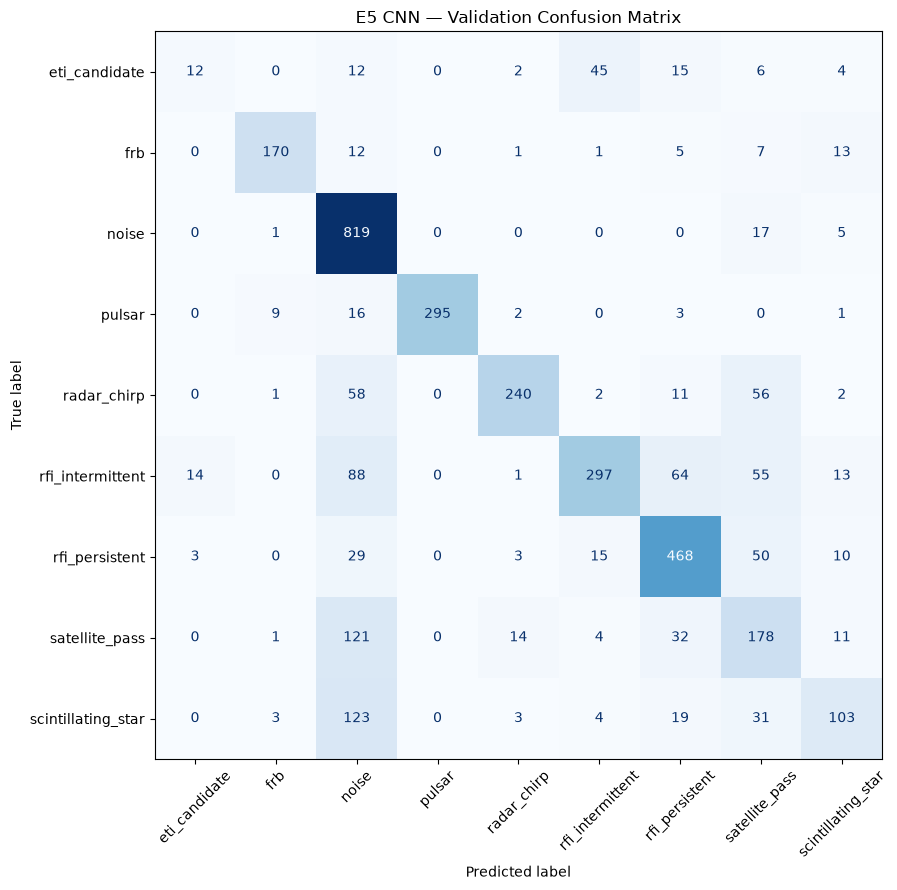

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    label_encoder.inverse_transform(all_targets),
    label_encoder.inverse_transform(all_preds),
    labels=label_encoder.classes_
)

fig, ax = plt.subplots(figsize=(11, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("E5 CNN — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [10]:
import pandas as pd

actual_counts = pd.Series(
    label_encoder.inverse_transform(all_targets)
).value_counts()

predicted_counts = pd.Series(
    label_encoder.inverse_transform(all_preds)
).value_counts()

prediction_summary = pd.DataFrame({
    "actual": actual_counts,
    "predicted": predicted_counts
}).fillna(0).astype(int)

display(prediction_summary)

,actual,predicted
eti_candidate,96,29
frb,209,185
noise,842,1278
pulsar,326,295
radar_chirp,370,266
rfi_intermittent,532,368
rfi_persistent,578,617
satellite_pass,361,400
scintillating_star,286,162


In [11]:
import numpy as np
import pandas as pd

# Fraction of pixels that are missing (zero) in each example.
missing_fraction = (X_train == 0).mean(axis=(1, 2, 3))

diagnostic = pd.DataFrame({
    "label": label_encoder.inverse_transform(y_encoded),
    "missing_fraction": missing_fraction
})

display(
    diagnostic.groupby("label")["missing_fraction"]
    .agg(["mean", "median", "std", "min", "max"])
    .sort_values("mean", ascending=False)
    .round(4)
)

,mean,median,std,min,max
label,,,,,
eti_candidate,0.0017,0.0,0.0040,0.0,0.0208
rfi_persistent,0.0016,0.0,0.0042,0.0,0.0417
radar_chirp,0.0016,0.0,0.0040,0.0,0.0208
frb,0.0016,0.0,0.0041,0.0,0.0417
satellite_pass,0.0016,0.0,0.0040,0.0,0.0208
noise,0.0015,0.0,0.0040,0.0,0.0312
pulsar,0.0015,0.0,0.0041,0.0,0.0312
rfi_intermittent,0.0015,0.0,0.0038,0.0,0.0208
scintillating_star,0.0013,0.0,0.0037,0.0,0.0208
